<a href="https://colab.research.google.com/github/anirbanghoshsbi/.github.io/blob/master/work/indicator/FII-oi-S.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

[*********************100%***********************]  1 of 1 completed


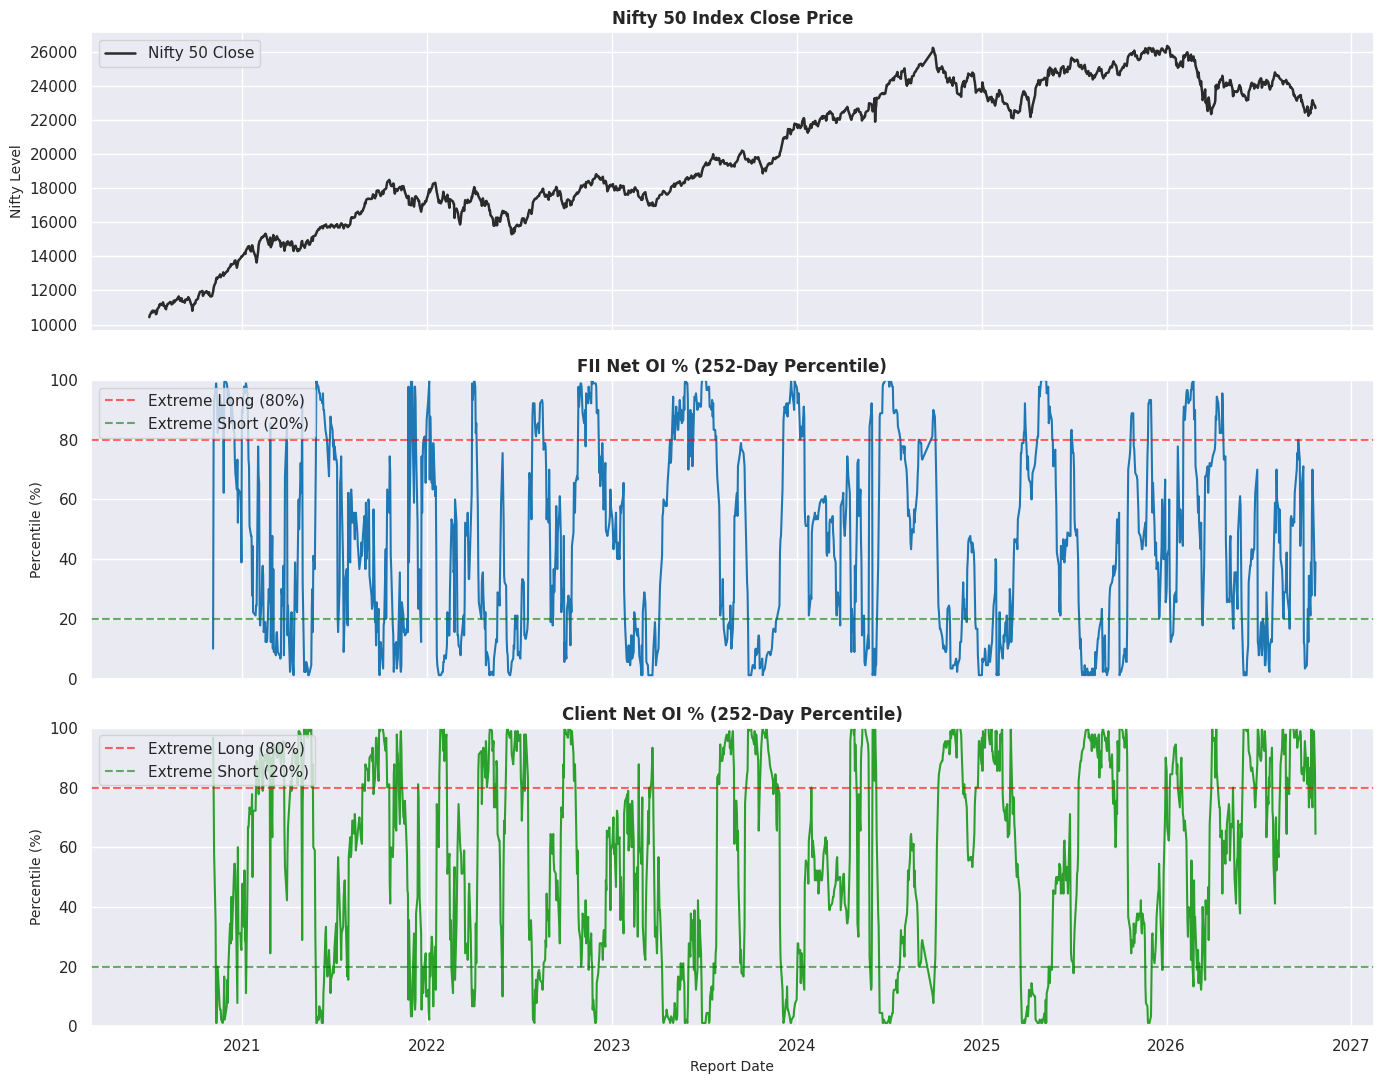

In [4]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import yfinance as yf

# 1. Load engineered OI data
df = pd.read_csv("engineered_oi_data.csv")
df['REPORT_DATE'] = pd.to_datetime(df['REPORT_DATE'])
df = df.sort_values('REPORT_DATE')

# Scale OI percentiles from ratio (0.0 to 1.0) to percentage (0 to 100)
df['FII_Net_OI_Pct_252D_Percentile_Scaled'] = df['FII_Net_OI_Pct_252D_Percentile'] * 100
df['Client_Net_OI_Pct_252D_Percentile_Scaled'] = df['Client_Net_OI_Pct_252D_Percentile'] * 100

# 2. Fetch Nifty 50 Close price data using yfinance
start_date = df['REPORT_DATE'].min().strftime('%Y-%m-%d')
end_date = df['REPORT_DATE'].max().strftime('%Y-%m-%d')

# Explicitly set auto_adjust=False to avoid future warnings
nifty_raw = yf.download('^NSEI', start=start_date, end=end_date, auto_adjust=False)

# Flatten MultiIndex columns safely
if isinstance(nifty_raw.columns, pd.MultiIndex):
    nifty = nifty_raw['Close'].copy()
else:
    nifty = nifty_raw[['Close']].copy()

# Reset index to bring Date out as a standard column
nifty = nifty.reset_index()

# Handle column naming dynamically regardless of ticker name in header
nifty.columns = ['REPORT_DATE', 'NIFTY_Close']
nifty['REPORT_DATE'] = pd.to_datetime(nifty['REPORT_DATE'])

# 3. Merge Nifty Close with OI Percentile DataFrame
merged_df = pd.merge(df, nifty, on='REPORT_DATE', how='inner')

# 4. Set visual style and setup 3 subplots
sns.set_theme(style="darkgrid")
fig, axes = plt.subplots(3, 1, figsize=(14, 11), sharex=True)

# Subplot 1: Nifty 50 Index Close Price
axes[0].plot(
    merged_df['REPORT_DATE'],
    merged_df['NIFTY_Close'],
    color='#2b2b2b',
    linewidth=1.8,
    label='Nifty 50 Close'
)
axes[0].set_title('Nifty 50 Index Close Price', fontsize=12, fontweight='bold')
axes[0].set_ylabel('Nifty Level', fontsize=10)
axes[0].legend(loc='upper left')

# Subplot 2: FII Net OI Percentile
sns.lineplot(
    data=merged_df,
    x='REPORT_DATE',
    y='FII_Net_OI_Pct_252D_Percentile_Scaled',
    ax=axes[1],
    color='#1f77b4',
    linewidth=1.5
)
axes[1].set_title('FII Net OI % (252-Day Percentile)', fontsize=12, fontweight='bold')
axes[1].set_ylabel('Percentile (%)', fontsize=10)
axes[1].set_ylim(0, 100)
axes[1].axhline(80, color='red', linestyle='--', alpha=0.6, label='Extreme Long (80%)')
axes[1].axhline(20, color='green', linestyle='--', alpha=0.6, label='Extreme Short (20%)')
axes[1].legend(loc='upper left')

# Subplot 3: Client Net OI Percentile
sns.lineplot(
    data=merged_df,
    x='REPORT_DATE',
    y='Client_Net_OI_Pct_252D_Percentile_Scaled',
    ax=axes[2],
    color='#2ca02c',
    linewidth=1.5
)
axes[2].set_title('Client Net OI % (252-Day Percentile)', fontsize=12, fontweight='bold')
axes[2].set_xlabel('Report Date', fontsize=10)
axes[2].set_ylabel('Percentile (%)', fontsize=10)
axes[2].set_ylim(0, 100)
axes[2].axhline(80, color='red', linestyle='--', alpha=0.6, label='Extreme Long (80%)')
axes[2].axhline(20, color='green', linestyle='--', alpha=0.6, label='Extreme Short (20%)')
axes[2].legend(loc='upper left')

# 5. Adjust layout and show plot
plt.tight_layout()
plt.show()

In [5]:
merged_df.head()


,REPORT_DATE,Client_Future Index Long,DII_Future Index Long,FII_Future Index Long,Pro_Future Index Long,Client_Future Index Short,DII_Future Index Short,FII_Future Index Short,Pro_Future Index Short,Client_Option Index Call Long,...,Total_Market_Index_Calls,Market_Index_PCR,FII_Net_Futures_252D_Percentile,FII_Net_OI_Pct_252D_Percentile,Client_Net_Futures_252D_Percentile,Client_Net_OI_Pct_252D_Percentile,FII_Trend_Status,FII_Net_OI_Pct_252D_Percentile_Scaled,Client_Net_OI_Pct_252D_Percentile_Scaled,NIFTY_Close
0,2020-07-01,137543,19680,39264,17942,115057,16252,53672,29448,679747,...,1073978,1.294662,NaN,NaN,NaN,NaN,neutral,NaN,NaN,10430.049805
1,2020-07-02,131430,19577,45179,19240,121716,16412,48255,29043,371747,...,670082,1.359484,NaN,NaN,NaN,NaN,neutral,NaN,NaN,10551.700195
2,2020-07-03,129469,19577,50589,20286,123380,20524,46889,29128,543542,...,913768,1.232496,NaN,NaN,NaN,NaN,neutral,NaN,NaN,10607.349609
3,2020-07-06,124179,19674,56993,21208,124685,24524,45142,27703,572955,...,1006540,1.308492,NaN,NaN,NaN,NaN,neutral,NaN,NaN,10763.650391
4,2020-07-07,140401,19674,52178,22819,127456,26456,45138,36022,602171,...,1023051,1.433940,NaN,NaN,NaN,NaN,neutral,NaN,NaN,10799.650391


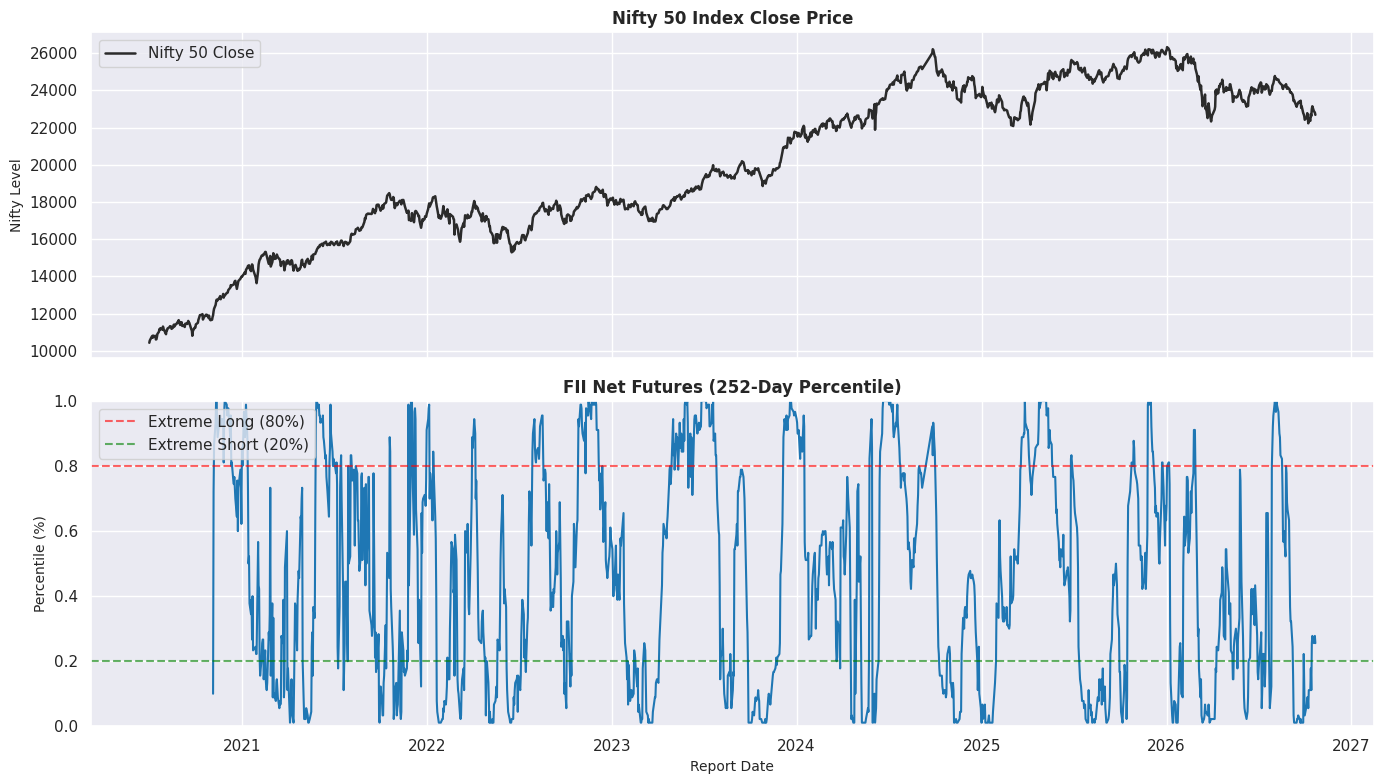

In [8]:
# 3. Create 2 Subplots
sns.set_theme(style="darkgrid")
fig, axes = plt.subplots(2, 1, figsize=(14, 8), sharex=True)

# Subplot 1: Nifty 50 Close Price
axes[0].plot(
    merged_df['REPORT_DATE'],
    merged_df['NIFTY_Close'],  # Replace 'NIFTY_CLOSE' with your exact column name if different (e.g. 'Close')
    color='#2b2b2b',
    linewidth=1.8,
    label='Nifty 50 Close'
)
axes[0].set_title('Nifty 50 Index Close Price', fontsize=12, fontweight='bold')
axes[0].set_ylabel('Nifty Level', fontsize=10)
axes[0].legend(loc='upper left')

# Subplot 2: FII Net Futures 252D Percentile
sns.lineplot(
    data=merged_df,
    x='REPORT_DATE',
    y='FII_Net_Futures_252D_Percentile',
    ax=axes[1],
    color='#1f77b4',
    linewidth=1.5
)
axes[1].set_title('FII Net Futures (252-Day Percentile)', fontsize=12, fontweight='bold')
axes[1].set_xlabel('Report Date', fontsize=10)
axes[1].set_ylabel('Percentile (%)', fontsize=10)
axes[1].set_ylim(0, 1)
axes[1].axhline(0.80, color='red', linestyle='--', alpha=0.6, label='Extreme Long (80%)')
axes[1].axhline(0.20, color='green', linestyle='--', alpha=0.6, label='Extreme Short (20%)')
axes[1].legend(loc='upper left')

# 4. Render plot
plt.tight_layout()
plt.show()

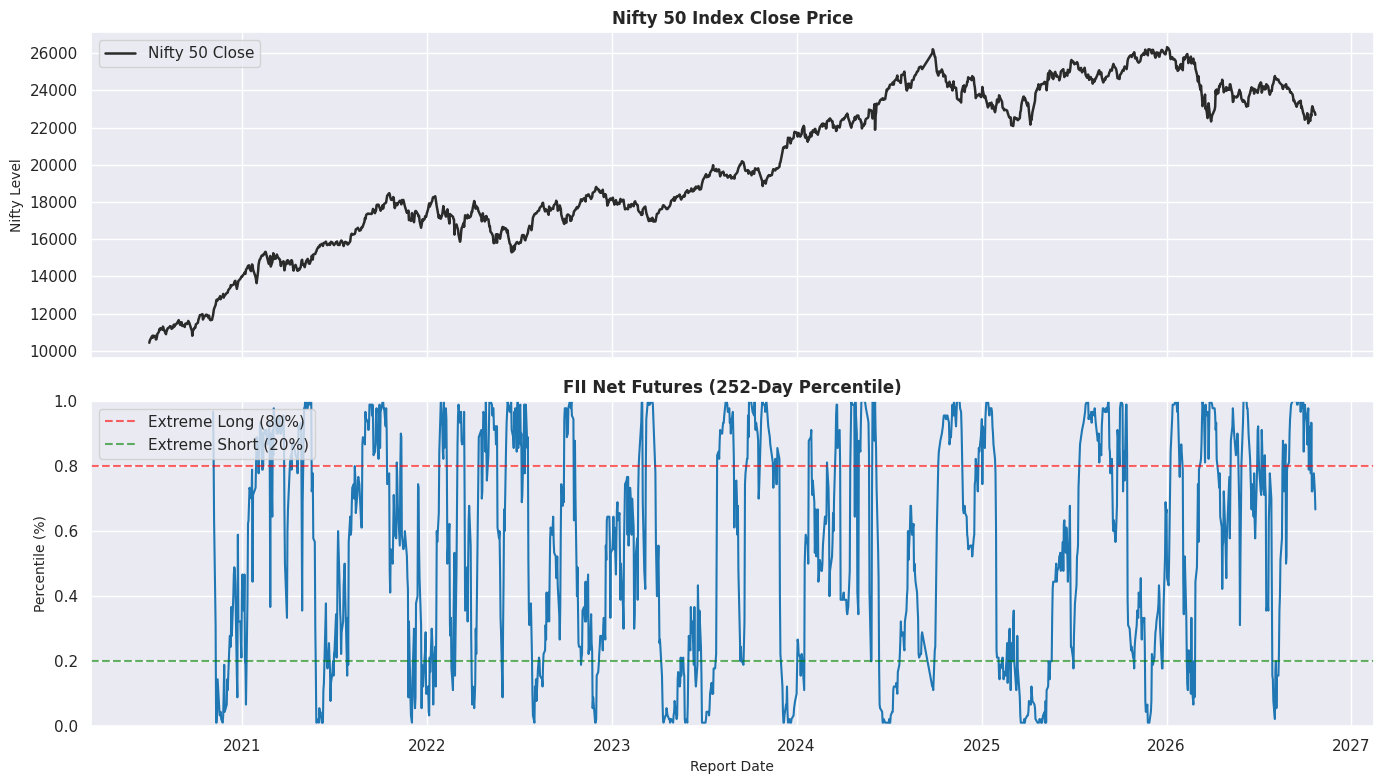

In [9]:
# 3. Create 2 Subplots
sns.set_theme(style="darkgrid")
fig, axes = plt.subplots(2, 1, figsize=(14, 8), sharex=True)

# Subplot 1: Nifty 50 Close Price
axes[0].plot(
    merged_df['REPORT_DATE'],
    merged_df['NIFTY_Close'],  # Replace 'NIFTY_CLOSE' with your exact column name if different (e.g. 'Close')
    color='#2b2b2b',
    linewidth=1.8,
    label='Nifty 50 Close'
)
axes[0].set_title('Nifty 50 Index Close Price', fontsize=12, fontweight='bold')
axes[0].set_ylabel('Nifty Level', fontsize=10)
axes[0].legend(loc='upper left')

# Subplot 2: FII Net Futures 252D Percentile
sns.lineplot(
    data=merged_df,
    x='REPORT_DATE',
    y='Client_Net_Futures_252D_Percentile',
    ax=axes[1],
    color='#1f77b4',
    linewidth=1.5
)
axes[1].set_title('Client Net Futures (252-Day Percentile)', fontsize=12, fontweight='bold')
axes[1].set_xlabel('Report Date', fontsize=10)
axes[1].set_ylabel('Percentile (%)', fontsize=10)
axes[1].set_ylim(0, 1)
axes[1].axhline(0.80, color='red', linestyle='--', alpha=0.6, label='Extreme Long (80%)')
axes[1].axhline(0.20, color='green', linestyle='--', alpha=0.6, label='Extreme Short (20%)')
axes[1].legend(loc='upper left')

# 4. Render plot
plt.tight_layout()
plt.show()